In [65]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

df = pd.read_csv('CleanedDataSet.csv') 

## 1. Baseline model : log(ROI)

In [66]:
df = df.replace(True, 1).replace(False, 0)
df['log_ROI'] = np.log(df['ROI'])

print(df.describe(), df.shape, sep="\n\n")

             Budget       Revenue  Number of Screens  Revenue Per Screen  \
count  1.698000e+03  1.698000e+03        1698.000000        1.698000e+03   
mean   1.501232e+08  2.378061e+08         554.485277        2.539380e+05   
std    2.434283e+08  6.134190e+08         783.007858        3.492042e+05   
min    3.250000e+05  7.250000e+03           1.000000        2.000000e+03   
25%    1.500000e+07  1.156250e+06          30.000000        3.079117e+04   
50%    5.500000e+07  1.250000e+07         200.000000        1.100000e+05   
75%    1.900000e+08  1.778325e+08         800.000000        3.336818e+05   
max    2.100000e+09  8.016120e+09        4600.000000        2.700000e+06   

       Movie_Scale          ROI      log_ROI  
count  1698.000000  1698.000000  1698.000000  
mean      6.013065     0.794755    -1.231928  
std       2.068723     1.056548     1.626850  
min       1.221000     0.000580    -7.452482  
25%       4.465000     0.084138    -2.475320  
50%       6.338000     0.335075  

In [67]:
bools = ['Remake', 'Franchise', 'Holiday']
genres = [  'Genre_adult', 'Genre_animation', 'Genre_comedy', 'Genre_documentary',
            'Genre_drama', 'Genre_fantasy', 'Genre_horror', 'Genre_love_story',
            'Genre_masala', 'Genre_mythological', 'Genre_rom_com', 'Genre_suspense',
            'Genre_thriller']
cast_novelty = ['New_Actor', 'New_Director', 'New_Music_Director']

focus_cols = bools + genres + cast_novelty
X = df[focus_cols]
Y = df['log_ROI']
X =sm.add_constant(X)
log_ROI_model = sm.OLS(Y, X).fit()
print(log_ROI_model.summary())

                            OLS Regression Results                            
Dep. Variable:                log_ROI   R-squared:                       0.302
Model:                            OLS   Adj. R-squared:                  0.294
Method:                 Least Squares   F-statistic:                     38.13
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.15e-116
Time:                        05:42:16   Log-Likelihood:                -2930.5
No. Observations:                1698   AIC:                             5901.
Df Residuals:                    1678   BIC:                             6010.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.6449      0

In [68]:
print(log_ROI_model.params)

const                -0.644937
Remake                1.089249
Franchise             1.172221
Holiday               0.105729
Genre_adult           0.622389
Genre_animation      -1.777286
Genre_comedy         -0.049682
Genre_documentary     2.581598
Genre_drama          -0.306931
Genre_fantasy        -0.870865
Genre_horror          0.198832
Genre_love_story     -0.203651
Genre_masala          0.858432
Genre_mythological   -0.714602
Genre_rom_com         0.444485
Genre_suspense       -0.769289
Genre_thriller        0.018160
New_Actor            -0.696731
New_Director         -0.729852
New_Music_Director   -0.451137
dtype: float64


## 2. Accounting For Scale

### Our major question, how to we cleanly account for the Scale of the Movie?

##### Simply taking ROI and considering the scale accounted is a bad decision, because the other factors maybe influenced by scale, higher scale of movie implies higher chance of holiday releases, lower chance of new crew, more reach etc., so inheritely there will be an effect on ROI.

    So we have decided to convert the continuous scale column into 9 parts in ranges (1, 2], (2, 3] .... (9, 10].
    We are not using a continuos scale and instead a linear scale, so that we can effectively and easily separate movies of similar .scale to compare and fit among them.

In [69]:
df['Scale_Bin'] = pd.cut(df['Movie_Scale'], bins=range(0, 11)).cat.remove_unused_categories()
print(df['Scale_Bin'].value_counts().sort_index())

Scale_Bin
(1, 2]      58
(2, 3]     127
(3, 4]     142
(4, 5]     211
(5, 6]     232
(6, 7]     271
(7, 8]     332
(8, 9]     254
(9, 10]     71
Name: count, dtype: int64


## 3. Scale-adjusted regression

The descriptive ROI-by-scale table that motivates this design lives in 2.EDA.ipynb (§9).


Now we re-fit the log(ROI) model **with the `Movie_Scale` bins included as dummy variables**.
Each film is compared only against films of a similar scale, which is exactly the
"like-for-like" comparison our research question demands.

    log(ROI) = intercept + focus_cols + one baseline shift per scale bin

The focus coefficients now answer: *within a given budget/screens band, does release strategy, genre, or crew novelty still move ROI?*

In [70]:
def clean_terms(model, names):
    """Collect params/p-values for binary predictors; patsy names them like 'Remake[T.1]'."""
    out = {}
    for name in names:
        matches = [k for k in model.params.index if k.split('[')[0] == name]
        out[name] = (model.params[matches[0]], model.pvalues[matches[0]]) if matches else (np.nan, np.nan)
    return pd.DataFrame(out, index=['coef', 'p']).T

# Baseline model
base_formula = "log_ROI ~ " + " + ".join(focus_cols)
base_model = smf.ols(base_formula, data=df).fit()

# Scale-adjusted model: focus coefficients + scale-bin dummies
scale_formula = base_formula + " + C(Scale_Bin)"
scale_model = smf.ols(scale_formula, data=df).fit()

base_terms = clean_terms(base_model, focus_cols)
scale_terms = clean_terms(scale_model, focus_cols)

comparison = pd.DataFrame({
    'coef (no scale)': base_terms['coef'],
    'p (no scale)': base_terms['p'],
    'coef (scale-adjusted)': scale_terms['coef'],
    'p (scale-adjusted)': scale_terms['p'],
})

comparison['significant before'] = comparison['p (no scale)'] < 0.05
comparison['significant after'] = comparison['p (scale-adjusted)'] < 0.05

print(f"R2 no scale = {base_model.rsquared:.3f}   |   R2 with scale = {scale_model.rsquared:.3f}")

print(f"Scale dummies alone add {100*(scale_model.rsquared - base_model.rsquared)/base_model.rsquared:.0f}% to the explained variance")
comparison.round(4)

R2 no scale = 0.302   |   R2 with scale = 0.549
Scale dummies alone add 82% to the explained variance


,coef (no scale),p (no scale),coef (scale-adjusted),p (scale-adjusted),significant before,significant after
Remake,1.0892,0.0000,0.3488,0.0028,True,True
Franchise,1.1722,0.0000,0.3356,0.0135,True,True
Holiday,0.1057,0.1267,-0.0153,0.7865,False,False
Genre_adult,0.6224,0.0021,1.6236,0.0000,True,True
Genre_animation,-1.7773,0.0046,-0.8917,0.0788,True,False
Genre_comedy,-0.0497,0.7376,-0.0010,0.9936,False,False
Genre_documentary,2.5816,0.0608,0.8236,0.4587,False,False
Genre_drama,-0.3069,0.0255,0.0258,0.8184,True,False
Genre_fantasy,-0.8709,0.0297,-1.0864,0.0008,True,True
Genre_horror,0.1988,0.3746,0.4384,0.0166,False,True


## 4. Recheck Model Fitting
**Checking for mismatches between raw ROI model and log(ROI) model, as deciding which is better**

In [71]:
raw_formula = "ROI ~ " + " + ".join(focus_cols) + " + C(Scale_Bin)"
raw_hc3 = smf.ols(raw_formula, data=df).fit(cov_type='HC3')
log_hc3 = smf.ols(scale_formula, data=df).fit(cov_type='HC3')

raw_terms = clean_terms(raw_hc3, focus_cols)
log_terms = clean_terms(log_hc3, focus_cols)

scalecmp = pd.DataFrame({
    'coef raw ROI (HC3)': raw_terms['coef'],
    'p raw ROI (HC3)': raw_terms['p'],
    'coef log ROI (HC3)': log_terms['coef'],
    'p log ROI (HC3)': log_terms['p'],
})
scalecmp['significant raw'] = scalecmp['p raw ROI (HC3)'] < 0.05
scalecmp['significant log'] = scalecmp['p log ROI (HC3)'] < 0.05
print(f"R2 raw ROI = {raw_hc3.rsquared:.3f}   |   R2 log ROI = {log_hc3.rsquared:.3f}")
scalecmp.round(4)

R2 raw ROI = 0.371   |   R2 log ROI = 0.549


,coef raw ROI (HC3),p raw ROI (HC3),coef log ROI (HC3),p log ROI (HC3),significant raw,significant log
Remake,0.3012,0.0222,0.3488,0.0001,True,True
Franchise,0.6676,0.0003,0.3356,0.0006,True,True
Holiday,0.0598,0.1802,-0.0153,0.7927,False,False
Genre_adult,0.5446,0.0000,1.6236,0.0000,True,True
Genre_animation,-0.4793,0.1105,-0.8917,0.2283,False,False
Genre_comedy,0.1737,0.0746,-0.0010,0.9928,False,False
Genre_documentary,0.4776,0.0422,0.8236,0.8370,True,False
Genre_drama,0.1640,0.0497,0.0258,0.8027,True,False
Genre_fantasy,-0.4356,0.0009,-1.0864,0.0000,True,True
Genre_horror,0.1614,0.2028,0.4384,0.0126,False,True


    📌 Result: Log Scale fits better

- R² rises from 0.371 (raw) to **0.549 (log)**, exactly as [3.DistributionFitting.ipynb](3.DistributionFitting.ipynb) predicts for the near-normal scale. 
- All log coefficients read as percentage effects on ROI.


## 5. Mediation — does budget act through screens?



We ask whether screens mediate budget's effect on revenue — i.e. *how* the
effect travels:

> > log(Budget) --a--> log(Screens) --b--> log(Revenue)

- **Path a**: log-screens on log-budget — money buying width.
- **Path b**: log-revenue on log-budget controlling for log-screens; the surviving
  budget coefficient is the **direct effect**.
- **Indirect effect = a × b**, bootstrapped 2,000 times (a product of two coefficients
  has no closed-form sampling distribution).


In [72]:
df['log_budget'] = np.log(df['Budget'])
df['log_screens'] = np.log(df['Number of Screens'])
df['log_revenue'] = np.log(df['Revenue'])

# Path a: budget -> screens
path_a = smf.ols("log_screens ~ log_budget", data=df).fit()
a = path_a.params['log_budget']

# Total effect: budget -> revenue (no mediator)
total_model = smf.ols("log_revenue ~ log_budget", data=df).fit()
c = total_model.params['log_budget']

# Direct effect: budget -> revenue controlling for screens
direct_model = smf.ols("log_revenue ~ log_budget + log_screens", data=df).fit()
b = direct_model.params['log_screens']
c_prime = direct_model.params['log_budget']

indirect = a * b
print(f"Path a  (budget -> screens):        {a:.4f}  (p = {path_a.pvalues['log_budget']:.2e})")
print(f"Total effect c (budget -> revenue): {c:.4f}  (p = {total_model.pvalues['log_budget']:.2e})")
print(f"Direct effect c' (controlling):     {c_prime:.4f}  (p = {direct_model.pvalues['log_budget']:.2e})")
print(f"Path b  (screens -> revenue):       {b:.4f}  (p = {direct_model.pvalues['log_screens']:.2e})")
print()
print(f"Indirect effect a*b = {indirect:.4f}  ->  {100*indirect/c:.1f}% of the total effect is mediated by screens")

Path a  (budget -> screens):        1.1756  (p = 0.00e+00)
Total effect c (budget -> revenue): 1.5007  (p = 0.00e+00)
Direct effect c' (controlling):     0.7569  (p = 1.40e-50)
Path b  (screens -> revenue):       0.6327  (p = 9.90e-56)

Indirect effect a*b = 0.7438  ->  49.6% of the total effect is mediated by screens


In [73]:
#Finding the 0.99CI for a*b
Xa = np.column_stack([np.ones(len(df)), df['log_budget']])
Xb = np.column_stack([np.ones(len(df)), df['log_budget'], df['log_screens']])
ya, yb = df['log_screens'].to_numpy(), df['log_revenue'].to_numpy()

rng2 = np.random.default_rng(42)
idx = rng2.integers(0, len(df), size=(2000, len(df)))
Xa_b, Xb_b, ya_b, yb_b = Xa[idx], Xb[idx], ya[idx], yb[idx]

pa_all = np.linalg.solve(np.einsum('bni,bnj->bij', Xa_b, Xa_b),
                         np.einsum('bni,bn->bi',  Xa_b, ya_b)[..., None])[..., 0][:, 1]
pb_all = np.linalg.solve(np.einsum('bni,bnj->bij', Xb_b, Xb_b),
                         np.einsum('bni,bn->bi',  Xb_b, yb_b)[..., None])[..., 0][:, 2]

lo, hi = np.percentile(pa_all * pb_all, [0.5, 99.5])
print(f"Indirect effect a*b = {indirect:.4f}, 99% bootstrap CI [{lo:.4f}, {hi:.4f}]")
print("The CI excludes 0 -> the mediation is statistically meaningful.")


Indirect effect a*b = 0.7438, 99% bootstrap CI [0.5922, 0.8825]
The CI excludes 0 -> the mediation is statistically meaningful.


    📌 Result:

a ≈ 1.18, b ≈ 0.63, indirect ≈ 0.74 (CI excludes 0) — **49.6% of budget's effect is mediated by screens**, validating the 50/50 weighting in [1.CleanUp.ipynb](1.CleanUp.ipynb).

## 6. Model diagnostics

- Running few checks on the scale-adjusted log(ROI) model

##### 1. Residuals vs Fitted & Quantile graph:
-   these help us determine the real confidence of the coefficients, that is the errors in the estimating paramters p and CI

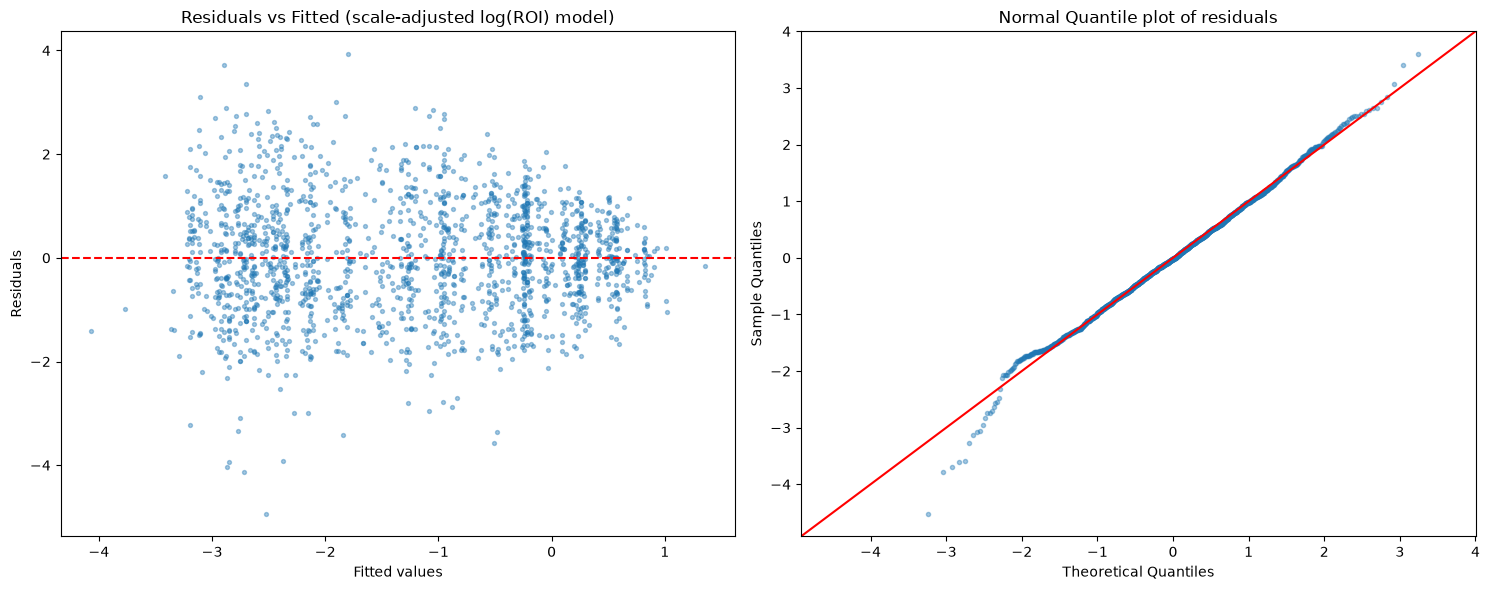

In [74]:
# Expected log(ROI) errors (ideal = 0) vs the actual deviations from the fitted log(ROI)

import matplotlib.pyplot as plt
from scipy import stats

fitted = scale_model.fittedvalues
resid = scale_model.resid

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(fitted, resid, s=8, alpha=0.4, color='tab:blue')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (scale-adjusted log(ROI) model)')

sm.qqplot(resid, line='45', fit=True, ax=axes[1], markersize=3, alpha=0.4)
axes[1].set_title('Normal Quantile plot of residuals')

plt.tight_layout()
fig.savefig("histograms/residual_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()

**📌 Result :**
>  The residuals fluctuate randomly around zero with no systematic curve or trend against the fitted values, so the linear specification is adequate 

> The errors behave like noise rather than structure, and the fitted coefficients are a trustworthy description of the data.

Two honest caveats, both visible in the plots: the QQ plot hugs the 45° line through the bulk but the **left tail is heavier than normal** (a handful of films lose far more than the model predicts — total flops), and the spread is mildly wider at low fitted values.

## 7. Validation — train / test split


We split the data 80/20, fit the scale-adjusted model on the training set, and check how
well it predicts ROI on the held-out test set. A large gap between train and test R²
would mean the model overfits; a small gap means the relationships are stable.

In [75]:
#Checking if our model has done overfitting
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

train_model = smf.ols(scale_formula, data=train_df).fit()

for name, frame in [('Train', train_df), ('Test', test_df)]:
    pred = train_model.predict(frame)
    r2 = r2_score(frame['log_ROI'], pred)
    rmse = np.sqrt(mean_squared_error(frame['ROI'], pred))
    print(f"{name:>5}: R2 = {r2:.3f}   RMSE = {rmse:.3f}")

print()
print(f"Train R2 = {train_model.rsquared:.3f} vs full-sample R2 = {scale_model.rsquared:.3f}")
print("A small train/test gap means the scale-adjusted model generalises within this dataset.")

Train: R2 = 0.554   RMSE = 2.292
 Test: R2 = 0.522   RMSE = 2.325

Train R2 = 0.554 vs full-sample R2 = 0.549
A small train/test gap means the scale-adjusted model generalises within this dataset.


## 8. Summary

- **Response.** The models explain **log(ROI)** — the near-normal scale validated in
  3.DistributionFitting.ipynb (R² 0.549 vs 0.371 for raw ROI); coefficients read as percentage
  effects on ROI, exp(β) − 1.

- **Scale dominates.** Adding the `Movie_Scale` bins raises R² sharply, and the raw
  group gaps (franchise, remake, holiday) shrink once films are compared within scale bands —
  this is the "budget illusion" at the heart of the project.

- **Mediation.** A large share of budget's effect on revenue flows through screens:
  big films earn more mostly because they open on many more screens.
  
- **Validation.** Train and test R² are close, so the fitted relationships are stable
  within this sample.
